In [34]:
%pip install datasets pymongo pandas sentence-transformers

In [35]:
%pip install -U transformers accelerate

In [36]:
from datasets import load_dataset

In [37]:
import pandas as pd

# 加载数据集

In [38]:
dataset=load_dataset("MongoDB/embedded_movies")

In [39]:
dataset

DatasetDict({
    train: Dataset({
        features: ['plot', 'runtime', 'genres', 'fullplot', 'directors', 'writers', 'countries', 'poster', 'languages', 'cast', 'title', 'num_mflix_comments', 'rated', 'imdb', 'awards', 'type', 'metacritic', 'plot_embedding'],
        num_rows: 1500
    })
})

In [40]:
dataset_df=pd.DataFrame(dataset["train"])

In [41]:
dataset_df.head()

,plot,runtime,genres,fullplot,directors,writers,countries,poster,languages,cast,title,num_mflix_comments,rated,imdb,awards,type,metacritic,plot_embedding
0,Young Pauline is left a lot of money when her ...,199.0,[Action],Young Pauline is left a lot of money when her ...,"[Louis J. Gasnier, Donald MacKenzie]","[Charles W. Goddard (screenplay), Basil Dickey...",[USA],https://m.media-amazon.com/images/M/MV5BMzgxOD...,[English],"[Pearl White, Crane Wilbur, Paul Panzer, Edwar...",The Perils of Pauline,0,None,"{'id': 4465, 'rating': 7.6, 'votes': 744}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[0.0007293965, -0.026834568, 0.013515796, -0.0..."
1,A penniless young man tries to save an heiress...,22.0,"[Comedy, Short, Action]",As a penniless man worries about how he will m...,"[Alfred J. Goulding, Hal Roach]",[H.M. Walker (titles)],[USA],https://m.media-amazon.com/images/M/MV5BNzE1OW...,[English],"[Harold Lloyd, Mildred Davis, 'Snub' Pollard, ...",From Hand to Mouth,0,TV-G,"{'id': 10146, 'rating': 7.0, 'votes': 639}","{'nominations': 1, 'text': '1 nomination.', 'w...",movie,NaN,"[-0.022837115, -0.022941574, 0.014937485, -0.0..."
2,"Michael ""Beau"" Geste leaves England in disgrac...",101.0,"[Action, Adventure, Drama]","Michael ""Beau"" Geste leaves England in disgrac...",[Herbert Brenon],"[Herbert Brenon (adaptation), John Russell (ad...",[USA],None,[English],"[Ronald Colman, Neil Hamilton, Ralph Forbes, A...",Beau Geste,0,None,"{'id': 16634, 'rating': 6.9, 'votes': 222}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[0.0002333049, -0.028511643, 0.014653289, -0.0..."
3,"Seeking revenge, an athletic young man joins t...",88.0,"[Adventure, Action]",A nobleman vows to avenge the death of his fat...,[Albert Parker],"[Douglas Fairbanks (story), Jack Cunningham (a...",[USA],https://m.media-amazon.com/images/M/MV5BMzU0ND...,None,"[Billie Dove, Tempe Pigott, Donald Crisp, Sam ...",The Black Pirate,1,None,"{'id': 16654, 'rating': 7.2, 'votes': 1146}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[-0.005927917, -0.033394486, 0.0015323418, -0...."
4,An irresponsible young millionaire changes his...,58.0,"[Action, Comedy, Romance]","The Uptown Boy, J. Harold Manners (Lloyd) is a...",[Sam Taylor],"[Ted Wilde (story), John Grey (story), Clyde B...",[USA],https://m.media-amazon.com/images/M/MV5BMTcxMT...,[English],"[Harold Lloyd, Jobyna Ralston, Noah Young, Jim...",For Heaven's Sake,0,PASSED,"{'id': 16895, 'rating': 7.6, 'votes': 918}","{'nominations': 1, 'text': '1 nomination.', 'w...",movie,NaN,"[-0.0059373598, -0.026604708, -0.0070914757, -..."


In [42]:
dataset_df.columns

Index(['plot', 'runtime', 'genres', 'fullplot', 'directors', 'writers',
       'countries', 'poster', 'languages', 'cast', 'title',
       'num_mflix_comments', 'rated', 'imdb', 'awards', 'type', 'metacritic',
       'plot_embedding'],
      dtype='object')

In [43]:
dataset_df['plot'][0]

"Young Pauline is left a lot of money when her wealthy uncle dies. However, her uncle's secretary has been named as her guardian until she marries, at which time she will officially take ..."

In [44]:
dataset_df['fullplot'][0]

'Young Pauline is left a lot of money when her wealthy uncle dies. However, her uncle\'s secretary has been named as her guardian until she marries, at which time she will officially take possession of her inheritance. Meanwhile, her "guardian" and his confederates constantly come up with schemes to get rid of Pauline so that he can get his hands on the money himself.'

In [45]:
dataset_df["num_mflix_comments"][0]

np.int64(0)

In [46]:
dataset_df['fullplot'].isnull().sum()

np.int64(48)

In [47]:
dataset_df.shape

(1500, 18)

In [48]:
dataset_df['poster'][0]

'https://m.media-amazon.com/images/M/MV5BMzgxODk1Mzk2Ml5BMl5BanBnXkFtZTgwMDg0NzkwMjE@._V1_SY1000_SX677_AL_.jpg'

In [49]:
dataset_df=dataset_df.dropna(subset=['fullplot'])

In [50]:
dataset_df['fullplot'].isnull().sum()

np.int64(0)

In [51]:
dataset_df.isnull().sum()

,0
plot,0
runtime,14
genres,0
fullplot,0
directors,12
writers,13
countries,0
poster,78
languages,1
cast,1


In [52]:
dataset_df=dataset_df.drop(columns=['plot_embedding'])

In [53]:
dataset_df.head(2)

,plot,runtime,genres,fullplot,directors,writers,countries,poster,languages,cast,title,num_mflix_comments,rated,imdb,awards,type,metacritic
0,Young Pauline is left a lot of money when her ...,199.0,[Action],Young Pauline is left a lot of money when her ...,"[Louis J. Gasnier, Donald MacKenzie]","[Charles W. Goddard (screenplay), Basil Dickey...",[USA],https://m.media-amazon.com/images/M/MV5BMzgxOD...,[English],"[Pearl White, Crane Wilbur, Paul Panzer, Edwar...",The Perils of Pauline,0,None,"{'id': 4465, 'rating': 7.6, 'votes': 744}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN
1,A penniless young man tries to save an heiress...,22.0,"[Comedy, Short, Action]",As a penniless man worries about how he will m...,"[Alfred J. Goulding, Hal Roach]",[H.M. Walker (titles)],[USA],https://m.media-amazon.com/images/M/MV5BNzE1OW...,[English],"[Harold Lloyd, Mildred Davis, 'Snub' Pollard, ...",From Hand to Mouth,0,TV-G,"{'id': 10146, 'rating': 7.0, 'votes': 639}","{'nominations': 1, 'text': '1 nomination.', 'w...",movie,NaN


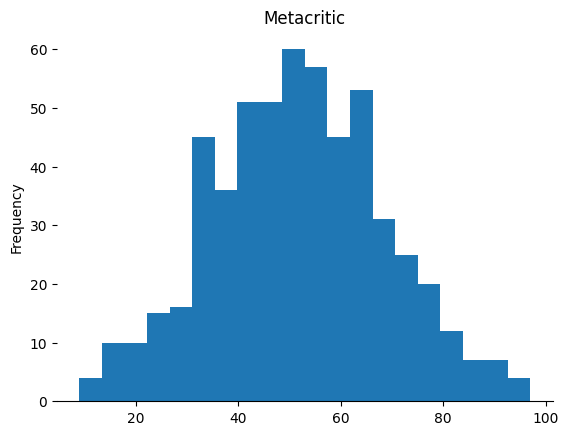

In [54]:
from matplotlib import pyplot as plt
dataset_df['metacritic'].plot(kind='hist', bins=20, title='Metacritic')
plt.gca().spines[['top','right', 'left']].set_visible(False)

# 构建Embedding

In [55]:
from sentence_transformers import SentenceTransformer
embedding_model=SentenceTransformer('thenlper/gte-large')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

In [56]:
dataset_df['fullplot'][2]

'Michael "Beau" Geste leaves England in disgrace and joins the infamous French Foreign Legion. He is reunited with his two brothers in North Africa, where they face greater danger from their own sadistic commander than from the rebellious Arabs.'

In [57]:
text='      ArithmeticError is a subclass of the built-in Exception class. It is raised when an error occurs in an arithmetic operation, such as division by zero or overflow. ArithmeticError is a base class for more specific arithmetic-related exceptions, including ZeroDivisionError, OverflowError, and FloatingPointError.'

In [58]:
text

'      ArithmeticError is a subclass of the built-in Exception class. It is raised when an error occurs in an arithmetic operation, such as division by zero or overflow. ArithmeticError is a base class for more specific arithmetic-related exceptions, including ZeroDivisionError, OverflowError, and FloatingPointError.'

In [59]:
text.strip()

'ArithmeticError is a subclass of the built-in Exception class. It is raised when an error occurs in an arithmetic operation, such as division by zero or overflow. ArithmeticError is a base class for more specific arithmetic-related exceptions, including ZeroDivisionError, OverflowError, and FloatingPointError.'

In [60]:
def get_embedding(text:str)->list[float]:
    if not text.strip():
        print('attempted to get embedding for empty text.')
        return []

    embedding=embedding_model.encode(text)
    return embedding.tolist()

In [63]:
# 替换成自己选择的embedding模型构建的embedding
# dataset_df['embedding']=dataset_df['fullplot'].apply(get_embedding)
dataset_df_20=dataset_df.head(20).copy()
dataset_df_20.loc[:,'embedding']=dataset_df_20['fullplot'].apply(get_embedding)

In [64]:
dataset_df_20.head(3)

,plot,runtime,genres,fullplot,directors,writers,countries,poster,languages,cast,title,num_mflix_comments,rated,imdb,awards,type,metacritic,embedding
0,Young Pauline is left a lot of money when her ...,199.0,[Action],Young Pauline is left a lot of money when her ...,"[Louis J. Gasnier, Donald MacKenzie]","[Charles W. Goddard (screenplay), Basil Dickey...",[USA],https://m.media-amazon.com/images/M/MV5BMzgxOD...,[English],"[Pearl White, Crane Wilbur, Paul Panzer, Edwar...",The Perils of Pauline,0,None,"{'id': 4465, 'rating': 7.6, 'votes': 744}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[-0.0092620849609375, -0.005054473876953125, -..."
1,A penniless young man tries to save an heiress...,22.0,"[Comedy, Short, Action]",As a penniless man worries about how he will m...,"[Alfred J. Goulding, Hal Roach]",[H.M. Walker (titles)],[USA],https://m.media-amazon.com/images/M/MV5BNzE1OW...,[English],"[Harold Lloyd, Mildred Davis, 'Snub' Pollard, ...",From Hand to Mouth,0,TV-G,"{'id': 10146, 'rating': 7.0, 'votes': 639}","{'nominations': 1, 'text': '1 nomination.', 'w...",movie,NaN,"[-0.002445220947265625, 0.0230865478515625, -0..."
2,"Michael ""Beau"" Geste leaves England in disgrac...",101.0,"[Action, Adventure, Drama]","Michael ""Beau"" Geste leaves England in disgrac...",[Herbert Brenon],"[Herbert Brenon (adaptation), John Russell (ad...",[USA],None,[English],"[Ronald Colman, Neil Hamilton, Ralph Forbes, A...",Beau Geste,0,None,"{'id': 16634, 'rating': 6.9, 'votes': 222}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[0.01221466064453125, -0.01146697998046875, -0..."


# 上传到mongodb

In [ ]:
uri='mongodb://<username>:<password>@ac-jitdjfy-shard-00-00.y7b1gpl.mongodb.net:27017,ac-jitdjfy-shard-00-01.y7b1gpl.mongodb.net:27017,ac-jitdjfy-shard-00-02.y7b1gpl.mongodb.net:27017/?ssl=true&replicaSet=atlas-ixzzmt-shard-0&authSource=admin'

In [66]:
from pymogo

In [67]:
from pymongo import MongoClient
client = MongoClient(uri)
try:
    client.admin.command("ping")
    print("Connected successfully")
    client.close()

except Exception as e:
    raise Exception(
        "The following error occurred: ", e)

Connected successfully


In [71]:
client=MongoClient(uri)

In [6]:
import requests

ip = requests.get("https://api.ipify.org", timeout=10).text.strip()
print(ip)

34.170.65.43


In [72]:
db=client['moviedb2']

In [73]:
collection=db['moviecollection2']

In [74]:
collection.insert_one({
    "name":"sunny",
    "designation":"genai engineer",
    "location":'bangaluru',
    'mailid':"sunny@example.com"
})

InsertOneResult(ObjectId('6adcb8c2887ff14c24ef25ac'), acknowledged=True)

In [75]:
collection.insert_one({
    "name":'dipesh',
    'designation':'ops manager',
    'location':'bangaluru'
})

InsertOneResult(ObjectId('6adcb9b9887ff14c24ef25ad'), acknowledged=True)

In [76]:
collection2=db['moviecollectionsecond']
collection2.insert_one({
    'name':'krish',
    'designation':'tech lead',
    'location':'bangaluru',
    'phonenumber':'123'
})

InsertOneResult(ObjectId('6adcba10887ff14c24ef25ae'), acknowledged=True)

In [77]:
collection.delete_many({})

DeleteResult({'n': 2, 'electionId': ObjectId('7fffffff000000000000009f'), 'opTime': {'ts': Timestamp(1792850484, 11), 't': 159}, 'ok': 1.0, '$clusterTime': {'clusterTime': Timestamp(1792850484, 11), 'signature': {'hash': b"\x93'\xbf\t\xf8@}z\x0b\xa3\xa0|L\xd66\xf3Oo\xa3\xd3", 'keyId': 7634944327357038593}}, 'operationTime': Timestamp(1792850484, 11)}, acknowledged=True)

In [79]:
dataset_df_20.tail(3)

,plot,runtime,genres,fullplot,directors,writers,countries,poster,languages,cast,title,num_mflix_comments,rated,imdb,awards,type,metacritic,embedding
17,Rick Leland makes no secret of the fact he has...,97.0,"[Action, Adventure, Drama]",Rick Leland makes no secret of the fact he has...,"[John Huston, Vincent Sherman]","[Richard Macaulay (screenplay), Robert Carson ...",[USA],https://m.media-amazon.com/images/M/MV5BYWYwZD...,"[English, Japanese]","[Humphrey Bogart, Mary Astor, Sydney Greenstre...",Across the Pacific,0,APPROVED,"{'id': 34428, 'rating': 6.9, 'votes': 2892}","{'nominations': 0, 'text': '1 win.', 'wins': 1}",movie,NaN,"[0.0262603759765625, 0.0027713775634765625, -0..."
18,An ex-pirate contends with rowdy buccaneers an...,87.0,"[Action, Adventure, Drama]",When notorious pirate Henry Morgan is made gov...,[Henry King],"[Ben Hecht (screenplay), Seton I. Miller (scre...",[USA],https://m.media-amazon.com/images/M/MV5BMTQ1OD...,"[English, Spanish]","[Tyrone Power, Maureen O'Hara, Laird Cregar, T...",The Black Swan,1,APPROVED,"{'id': 34522, 'rating': 7.0, 'votes': 2779}","{'nominations': 3, 'text': 'Won 1 Oscar. Anoth...",movie,NaN,"[0.02935791015625, -0.005344390869140625, -0.0..."
19,A boy raised by wolves tries to adapt to human...,108.0,"[Action, Adventure, Family]","Teenaged Mowgli, who was raised by wolves, app...",[Zoltan Korda],[Laurence Stallings (adaptation)],"[USA, UK]",https://m.media-amazon.com/images/M/MV5BZDhhNG...,[English],"[Sabu, Joseph Calleia, John Qualen, Frank Puglia]",Jungle Book,0,APPROVED,"{'id': 34928, 'rating': 6.8, 'votes': 2569}","{'nominations': 0, 'text': 'Nominated for 4 Os...",movie,NaN,"[-0.00823211669921875, 0.008270263671875, -0.0..."


In [80]:
document=dataset_df_20.to_dict('records')
collection.insert_many(document)
print('data inserted successfully')

data inserted successfully


# Data retrieval

In [81]:
{
 "fields": [{
     "numDimensions": 1024,
     "path": "embedding",
     "similarity": "cosine",
     "type": "vector"
   }]
}

{'fields': [{'numDimensions': 1024,
   'path': 'embedding',
   'similarity': 'cosine',
   'type': 'vector'}]}

In [82]:
user_query='what is the best horror movie?'
query_embedding=get_embedding(user_query)
print(query_embedding)

[0.031982421875, -0.016387939453125, -0.034637451171875, 0.0014238357543945312, -0.0016651153564453125, -0.0122222900390625, -0.0154876708984375, 0.040252685546875, -0.00830078125, 0.0273590087890625, 0.032440185546875, -0.0069732666015625, 0.0140838623046875, -0.032073974609375, -0.00865936279296875, -0.0281219482421875, -0.03546142578125, -0.02313232421875, -0.02154541015625, 0.01007080078125, -0.00897216796875, 0.006679534912109375, -0.0606689453125, -0.01384735107421875, -0.020751953125, 0.0167388916015625, 0.0240325927734375, -0.0117950439453125, 0.036773681640625, 0.0814208984375, 0.00792694091796875, -0.041717529296875, 0.043182373046875, -0.038360595703125, -0.0279998779296875, -0.01898193359375, 0.0660400390625, -0.0005784034729003906, -0.02105712890625, -0.036956787109375, 0.02020263671875, 0.0028209686279296875, 0.05584716796875, -0.00920867919921875, -0.046661376953125, -0.00893402099609375, 0.02752685546875, -0.0150299072265625, 0.0017328262329101562, -0.04376220703125, -0

In [ ]:
pipeline = [

    {
        "$vectorSearch": {
            "index": "vector_index",
            "queryVector": query_embedding,
            "path": "embedding",
            "numCandidates": 150,  # Number of candidate matches to consider
            "limit": 4,  # Return top 4 matches
        }
    },
    {
        #伴随检索出的embedding附带的其它信息
        "$project": {
            "fullplot": 1,  # Include the plot field
            "title": 1,  # Include the title field
            "genres": 1,  # Include the genres field
            "score": {"$meta": "vectorSearchScore"},  # Include the search score
        }
    }
]

In [84]:
collection.aggregate(pipeline)

In [85]:
list(collection.aggregate(pipeline))

[{'_id': ObjectId('6adcbab5887ff14c24ef25bc'),
  'genres': ['Action', 'Drama', 'Musical'],
  'fullplot': "Story of the great fire of 1871. Fictional story of two sons of Mrs. O'Leary (the owner of the cow which started the fire), one a rogue (Power) the other a lawyer (Ameche). One of the most expensive films of its time ($1.8 million).",
  'title': 'In Old Chicago',
  'score': 0.8702982664108276},
 {'_id': ObjectId('6adcbab5887ff14c24ef25b6'),
  'genres': ['Action', 'Crime', 'Drama'],
  'fullplot': "Johnny Lovo rises to the head of the bootlegging crime syndicate on the south side of Chicago following the murder of former head, Big Louis Costillo. Johnny contracted Big Louis' bodyguard, Tony Camonte, to make the hit on his boss. Tony becomes Johnny's second in command. Johnny is not averse to killing anyone who gets in his and Johnny's way. As Tony is thinking bigger than Johnny and is not afraid of anyone or anything, Tony increasingly makes decisions on his own instead of following 

In [86]:
def vector_search(user_query,collection):

  query_embedding=get_embedding(user_query)
  print(query_embedding)

  if query_embedding is None:
    return "Invalid query or embeddig is failed"

  pipeline=[

            {
                "$vectorSearch":{

                "index": "vector_index",
                "queryVector": query_embedding,
                "path": "embedding",
                "numCandidates": 150,  # Number of candidate matches to consider
                "limit": 4,  # Return top 4 matches


                }

            },

              {
                 "$project":{

                "fullplot": 1,  # Include the plot field
                "title": 1,  # Include the title field
                "genres": 1,  # Include the genres field
                "score": {"$meta": "vectorSearchScore"},  # Include the search score
                 }

            }

           ]

  result=collection.aggregate(pipeline)
  return list(result)

In [87]:
vector_search("what is the best horror movie to watch and why?",collection)

[0.0192108154296875, -0.0154571533203125, -0.039581298828125, 0.002376556396484375, -0.002635955810546875, 0.005092620849609375, -0.00751495361328125, 0.04510498046875, -0.01806640625, 0.04296875, 0.01346588134765625, -0.0028820037841796875, 0.0055084228515625, -0.03125, -0.004093170166015625, -0.0310516357421875, -0.04107666015625, -0.030120849609375, -0.03216552734375, 0.0275115966796875, -0.00313568115234375, 0.0168304443359375, -0.044189453125, -0.0240478515625, -0.01556396484375, 0.0178680419921875, 0.0216522216796875, -0.030426025390625, 0.0458984375, 0.072265625, 0.002323150634765625, -0.0460205078125, 0.0261688232421875, -0.048980712890625, -0.03350830078125, -0.01010894775390625, 0.054931640625, 0.0016460418701171875, -0.002689361572265625, -0.038055419921875, 0.016632080078125, 0.01432037353515625, 0.0455322265625, -0.0112457275390625, -0.05047607421875, 0.0024089813232421875, 0.017913818359375, -0.0300750732421875, -0.00769805908203125, -0.021697998046875, 0.0025100708007812

[{'_id': ObjectId('6adcbab5887ff14c24ef25bc'),
  'genres': ['Action', 'Drama', 'Musical'],
  'fullplot': "Story of the great fire of 1871. Fictional story of two sons of Mrs. O'Leary (the owner of the cow which started the fire), one a rogue (Power) the other a lawyer (Ameche). One of the most expensive films of its time ($1.8 million).",
  'title': 'In Old Chicago',
  'score': 0.8712419271469116},
 {'_id': ObjectId('6adcbab5887ff14c24ef25b6'),
  'genres': ['Action', 'Crime', 'Drama'],
  'fullplot': "Johnny Lovo rises to the head of the bootlegging crime syndicate on the south side of Chicago following the murder of former head, Big Louis Costillo. Johnny contracted Big Louis' bodyguard, Tony Camonte, to make the hit on his boss. Tony becomes Johnny's second in command. Johnny is not averse to killing anyone who gets in his and Johnny's way. As Tony is thinking bigger than Johnny and is not afraid of anyone or anything, Tony increasingly makes decisions on his own instead of following 

In [88]:
def get_search_result(query,collection):

  get_knowledge=vector_search(query,collection)

  search_result=""

  for result in get_knowledge:
        search_result += f"Title: {result.get('title', 'N/A')}, Plot: {result.get('fullplot', 'N/A')}\n"

  return search_result

In [89]:
query="what is the best comedy movie to watch and why?"

In [90]:
collection

Collection(Database(MongoClient(host=['ac-jitdjfy-shard-00-00.y7b1gpl.mongodb.net:27017', 'ac-jitdjfy-shard-00-02.y7b1gpl.mongodb.net:27017', 'ac-jitdjfy-shard-00-01.y7b1gpl.mongodb.net:27017'], document_class=dict, tz_aware=False, connect=True, replicaset='atlas-ixzzmt-shard-0', authsource='admin', tls=True), 'moviedb2'), 'moviecollection2')

In [91]:
source_information=get_search_result(query,collection)

[0.0196533203125, -0.0235443115234375, -0.031463623046875, 0.01499176025390625, -0.016357421875, -0.0168914794921875, -0.0119171142578125, 0.0416259765625, -0.0133514404296875, 0.0443115234375, 0.0045928955078125, 0.01053619384765625, 0.01279449462890625, -0.04827880859375, 0.005619049072265625, -0.0313720703125, -0.03753662109375, -0.037261962890625, -0.02972412109375, 0.0193634033203125, 0.004528045654296875, 0.0165863037109375, -0.034332275390625, -0.00928497314453125, 0.00821685791015625, 0.0203399658203125, -0.0095062255859375, 0.0005927085876464844, 0.052001953125, 0.0738525390625, 0.012939453125, -0.05584716796875, 0.0189666748046875, -0.060791015625, 0.011138916015625, -0.033203125, 0.0263519287109375, 0.0185089111328125, -0.0117340087890625, -0.04498291015625, -0.03619384765625, -0.0213165283203125, 0.038604736328125, -0.027679443359375, -0.05560302734375, 0.0015726089477539062, 0.01345062255859375, -0.023895263671875, -0.0080413818359375, -0.0218505859375, 0.01207733154296875

In [92]:
source_information

"Title: For Heaven's Sake, Plot: The Uptown Boy, J. Harold Manners (Lloyd) is a millionaire playboy who falls for the Downtown Girl, Hope (Ralston) who works in Brother Paul's (Weigel) mission. In order to build up attendance, and win Hope's attention, Harold runs through town causing trouble, and winds up with a crowd chasing him right into the mission. He eventually wins the girl and they marry, but not without some interference from his high-brow friends.\nTitle: In Old Chicago, Plot: Story of the great fire of 1871. Fictional story of two sons of Mrs. O'Leary (the owner of the cow which started the fire), one a rogue (Power) the other a lawyer (Ameche). One of the most expensive films of its time ($1.8 million).\nTitle: The Crowd Roars, Plot: Famous motor-racing champion Joe Greer returns to his hometown to compete in a local race. He discovers his younger brother has aspirations to become a racing champion and during the race Joe loses his nerve when another driver his killed, lea

In [93]:
combined_information = f"Query: {query}\nContinue to answer the query by using the Search Results:\n{source_information}."

print(combined_information)

Query: what is the best comedy movie to watch and why?
Continue to answer the query by using the Search Results:
Title: For Heaven's Sake, Plot: The Uptown Boy, J. Harold Manners (Lloyd) is a millionaire playboy who falls for the Downtown Girl, Hope (Ralston) who works in Brother Paul's (Weigel) mission. In order to build up attendance, and win Hope's attention, Harold runs through town causing trouble, and winds up with a crowd chasing him right into the mission. He eventually wins the girl and they marry, but not without some interference from his high-brow friends.
Title: In Old Chicago, Plot: Story of the great fire of 1871. Fictional story of two sons of Mrs. O'Leary (the owner of the cow which started the fire), one a rogue (Power) the other a lawyer (Ameche). One of the most expensive films of its time ($1.8 million).
Title: The Crowd Roars, Plot: Famous motor-racing champion Joe Greer returns to his hometown to compete in a local race. He discovers his younger brother has aspir

# Generation

In [94]:
%pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 10.8 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.3.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.


In [ ]:
HF_TOKEN='input your token'

In [96]:
from huggingface_hub import notebook_login
notebook_login()

In [98]:
from transformers import AutoTokenizer, AutoModelForCausalLM
tokenizer=AutoTokenizer.from_pretrained("google/gemma-2b-it")

config.json:   0%|          | 0.00/627 [00:00<?, ?B/s]

[transformers] We found `hidden_act="gelu"` in this Gemma config. This is a legacy value of the official releases but it is meant to target the tanh approximation. Setting `hidden_act="gelu_pytorch_tanh"` instead.


tokenizer_config.json:   0%|          | 0.00/34.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

In [99]:
# CPU Enabled uncomment below 👇🏽
model = AutoModelForCausalLM.from_pretrained("google/gemma-2b-it")
# GPU Enabled use below 👇🏽
# model = AutoModelForCausalLM.from_pretrained("google/gemma-2b-it", device_map="auto")

model.safetensors.index.json:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/164 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

In [100]:
import torch
print(torch.cuda.is_available())

False


In [ ]:
# Moving tensors to GPU
input_ids = tokenizer(combined_information, return_tensors="pt")

In [102]:
response = model.generate(**input_ids, max_new_tokens=500)

In [103]:
print(tokenizer.decode(response[0]))

<bos>Query: what is the best comedy movie to watch and why?
Continue to answer the query by using the Search Results:
Title: For Heaven's Sake, Plot: The Uptown Boy, J. Harold Manners (Lloyd) is a millionaire playboy who falls for the Downtown Girl, Hope (Ralston) who works in Brother Paul's (Weigel) mission. In order to build up attendance, and win Hope's attention, Harold runs through town causing trouble, and winds up with a crowd chasing him right into the mission. He eventually wins the girl and they marry, but not without some interference from his high-brow friends.
Title: In Old Chicago, Plot: Story of the great fire of 1871. Fictional story of two sons of Mrs. O'Leary (the owner of the cow which started the fire), one a rogue (Power) the other a lawyer (Ameche). One of the most expensive films of its time ($1.8 million).
Title: The Crowd Roars, Plot: Famous motor-racing champion Joe Greer returns to his hometown to compete in a local race. He discovers his younger brother has 